# scVI

In this notebook: 

- 26 patients, `fold_5` (5 patient-level folds stratified by subtype).
- 2500 per-patient HVG selected on train cells only, plus ESR1/PGR/ERBB2 (`src/hvg.py`).
- 10 latent dimensions.
- Metrics from `src/metrics.py`, computed on the test patients' cells.

**What scVI adds over PCA** (Lopez et al., 2018):
1. It models the raw counts with a negative binomial (NB) instead of a Gaussian on log-normalised data.
2. Sequencing depth (library size $\ell_n$) is a separate factor, so $z_n$ does not have to store it:
   $x_{ng} \sim \mathrm{NB}(\ell_n\,\rho_g(z_n, s_n),\ \theta_g)$
3. The patient $s_n$ can be given to the decoder as a batch covariate, so $z_n$ does not have to store it either.

| Model | Input | Patient given to the model? |
|---|---|---|
| PCA (baseline) | log1p CP10k | no |
| scVI, no batch | raw counts | no |
| scVI, batch = patient | raw counts | yes (decoder only) |

In [1]:
import sys, subprocess, pathlib
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    subprocess.run("pip -q install scvi-tools scanpy", shell=True, check=True)
    REPO = pathlib.Path("/content/DeepGen-Oncology")
    if not REPO.exists():
        subprocess.run(f"git clone -q https://github.com/alvarodca/DeepGen-Oncology.git {REPO}", shell=True, check=True)
    if not (REPO / "data" / "wu_2021_breast_cancer.h5ad").exists():   # path already listed in src/data.py
        subprocess.run([sys.executable, "-c", "import sys; sys.path.insert(0, 'data'); "
                        "from load_data import download_from_cellxgene; download_from_cellxgene()"],
                       cwd=REPO, check=True)
    from google.colab import drive
    drive.mount("/content/drive")   # results survive a disconnect; re-running skips finished folds
    OUT_DIR = pathlib.Path("/content/drive/MyDrive/results_scvi")
else:
    REPO = pathlib.Path.cwd() if (pathlib.Path.cwd() / "src").exists() else pathlib.Path.cwd().parent / "DeepGen-Oncology"
    OUT_DIR = pathlib.Path.cwd() / "results"
OUT_DIR.mkdir(exist_ok=True)
sys.path.insert(0, str(REPO))

In [2]:
import time, warnings, gc
from src import data as D, hvg as H, metrics as M, splits as S
import numpy as np, pandas as pd
import scanpy as sc, scvi, torch
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

scvi.settings.seed = S.SEED
ACCEL = "gpu" if torch.cuda.is_available() else "cpu"
print("scvi-tools", scvi.__version__, "| device:", ACCEL)

/Users/almudenamartin/Desktop/ML_EN_SALUD/FINAL_PROJECT/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Seed set to 42


scvi-tools 1.5.2 | device: cpu


## Data and folds

In [3]:
adata = D.load_adata()      # X = raw counts, layers['lognorm'] = log1p CP10k
D.attach_folds(adata)       # fold_5 per cell, via donor_id

# Save RAM: keep each cell's total counts and drop the all-genes lognorm layer.
# PCA only needs lognorm on the HVG of each fold, rebuilt below with lognorm()
# (log1p(counts / total * 1e4), the same values as the h5ad's original X).
adata.obs["total_counts"] = np.asarray(adata.X.sum(1)).ravel()
del adata.layers["lognorm"]; gc.collect()
print(adata.shape)
adata.obs.drop_duplicates("donor_id").groupby("fold_5", observed=True)["subtype"].value_counts().unstack(fill_value=0)

(100064, 28523)


subtype,ER+,HER2+,TNBC
fold_5,,,
0,2,1,2
1,2,1,2
2,2,1,2
3,3,1,2
4,2,1,2


## Models

- **scVI:** `n_latent = 10`, NB likelihood, scvi-tools defaults otherwise. Epochs from the scvi-tools heuristic (≈100 here) with early stopping on a 10% validation split of the **train** cells; `batch_size = 512`, as in `MrVI.ipynb`.
- **Test cells:** the scVI encoder does not use the batch, so a test cell's $z$ comes from its counts alone, with no training on the test patients (same query step as `MrVI.ipynb`).
- **PCA:** same recipe as `PCA.ipynb` (scale and loadings from train, test projected).

In [4]:
N_HVG, N_LATENT = 2500, 10
VARIANTS = {"scVI_nobatch": None, "scVI_patient": "donor_id"}


def lognorm(a):
    # log1p CP10k with the cell's total over ALL genes (identical to the original layer)
    X = a.X.multiply(1e4 / a.obs["total_counts"].values[:, None]).tocsr().astype(np.float32)
    X.data = np.log1p(X.data)
    return X


def fit_scvi(adata_tr, batch_key):
    a = adata_tr.copy()
    scvi.model.SCVI.setup_anndata(a, batch_key=batch_key)
    m = scvi.model.SCVI(a, n_latent=N_LATENT, gene_likelihood="nb")
    m.train(batch_size=512, early_stopping=True, accelerator=ACCEL, enable_progress_bar=False)
    return m


def query(model, adata_any):
    # Model for new cells: test patients are new batch categories, and the
    # encoder ignores the batch, so no training on them is needed.
    assert not model.module.encode_covariates
    a = adata_any.copy()
    scvi.model.SCVI.prepare_query_anndata(a, model)
    q = scvi.model.SCVI.load_query_data(a, model)
    q.is_trained_ = True
    return q, a


def fit_project_pca(adata_tr, adata_te):
    dense = lambda X: X.toarray() if hasattr(X, "toarray") else np.asarray(X)
    a = adata_tr.copy(); a.X = dense(a.layers["lognorm"]).astype(np.float32)
    sc.pp.scale(a, max_value=10); sc.tl.pca(a, n_comps=N_LATENT, random_state=S.SEED)
    mu, sd = a.var["mean"].values.astype(np.float32), a.var["std"].values.astype(np.float32)
    sd[sd == 0] = 1
    Xte = np.minimum((dense(adata_te.layers["lognorm"]).astype(np.float32) - mu) / sd, 10)
    return ((Xte - dense(a.X).mean(0)) @ a.varm["PCs"]).astype(np.float32)


def scores(Z, te):
    return M.evaluate_embedding(Z=Z, cell_type=adata.obs["celltype_major"].values[te],
                                patient=adata.obs["donor_id"].values[te],
                                batch_run=adata.obs["batch_run"].values[te], k=50, seed=S.SEED)

## 5-fold cross-validation

Per fold: HVG on train -> fit PCA and both scVI variants on train -> embed the test patients -> score.

In [5]:
CSV = OUT_DIR / "scvi_5fold_metrics.csv"
rows = pd.read_csv(CSV, dtype={"fold": str}).to_dict("records") if CSV.exists() else []
done = {r["fold"] for r in rows}
for fold, tr, te in D.iter_folds(adata, "fold_5"):
    if fold in done and fold != "0":   # fold 0 always runs: its models feed the figures below
        print(f"fold {fold}: already in {CSV.name}, skipped"); continue
    rows = [r for r in rows if r["fold"] != fold]
    t0 = time.time()
    hvg = H.select_hvg_train(adata, tr, n_top=N_HVG)
    a_tr, a_te = adata[tr, hvg].copy(), adata[te, hvg].copy()
    a_tr.layers["lognorm"], a_te.layers["lognorm"] = lognorm(a_tr), lognorm(a_te)

    Zs, models = {"PCA": fit_project_pca(a_tr, a_te)}, {}
    for name, bk in VARIANTS.items():
        models[name] = fit_scvi(a_tr, bk)
        q, a = query(models[name], a_te)
        Zs[name] = q.get_latent_representation(a)

    for name, Z in Zs.items():
        rows.append({"model": name, "fold": fold, **scores(Z, te)})
    if fold == "0":   # kept for the figures below
        Z0, te0, hvg0, m0 = Zs, te, hvg, models["scVI_nobatch"]
    pd.DataFrame(rows).to_csv(CSV, index=False)
    print(f"fold {fold}: {tr.sum():,} train / {te.sum():,} test cells, {len(hvg)} HVG, {time.time()-t0:.0f}s")
    del a_tr, a_te, models, Zs; gc.collect(); torch.cuda.empty_cache()   # free RAM before the next fold

res = pd.DataFrame(rows)

fold 3: already in scvi_5fold_metrics.csv, skipped
fold 2: already in scvi_5fold_metrics.csv, skipped


GPU available: True (mps), used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


`Trainer.fit` stopped: `max_epochs=96` reached.


INFO     Found 100.0% reference vars in query data.                                                                


... (24 outputs left out)

💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


`Trainer.fit` stopped: `max_epochs=102` reached.


INFO     Found 100.0% reference vars in query data.                                                                


fold 0: 78,344 train / 21,720 test cells, 2503 HVG, 2395s


In [6]:
ORDER = ["PCA", "scVI_nobatch", "scVI_patient"]
# Batch_Run_Entropy is left out: test patients almost never share a run, so it is ~equal to Patient_Entropy (kept in the CSV)
METRICS = ["ARI", "NMI", "ASW_celltype", "ASW_patient", "Patient_Entropy"]
summary = res.groupby("model")[METRICS].agg(["mean", "std"]).loc[ORDER]
table = pd.DataFrame({m: summary[m]["mean"].map("{:.3f}".format) + " ± " + summary[m]["std"].map("{:.3f}".format)
                      for m in METRICS})
table.to_csv(OUT_DIR / "scvi_5fold_summary.csv")
table

,ARI,NMI,ASW_celltype,ASW_patient,Patient_Entropy
model,,,,,
PCA,0.738 ± 0.078,0.762 ± 0.032,0.676 ± 0.021,0.039 ± 0.011,0.236 ± 0.058
scVI_nobatch,0.592 ± 0.096,0.766 ± 0.043,0.641 ± 0.013,0.094 ± 0.025,0.172 ± 0.036
scVI_patient,0.658 ± 0.181,0.792 ± 0.061,0.643 ± 0.017,0.041 ± 0.010,0.286 ± 0.054


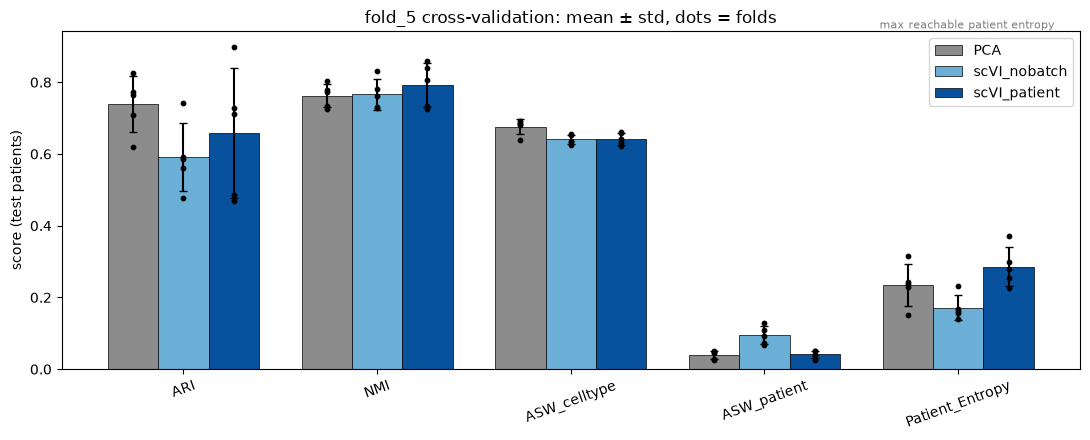

In [7]:
colors = {"PCA": "#8c8c8c", "scVI_nobatch": "#6baed6", "scVI_patient": "#08519c"}
fig, ax = plt.subplots(figsize=(11, 4.5))
w = 0.26
for i, name in enumerate(ORDER):
    mu, sd = summary.loc[name].xs("mean", level=1), summary.loc[name].xs("std", level=1)
    x = np.arange(len(METRICS)) + (i - 1) * w
    ax.bar(x, mu, w, yerr=sd, capsize=3, color=colors[name], label=name, edgecolor="black", linewidth=0.5)
    pts = res[res.model == name]
    for j, m in enumerate(METRICS):
        ax.scatter(np.full(len(pts), x[j]), pts[m], s=10, color="black", zorder=3)
ax.axhline(0.9416, ls=":", color="gray")
ax.text(len(METRICS) - 0.5, 0.95, "max reachable patient entropy", ha="right", fontsize=8, color="gray")
ax.set_xticks(np.arange(len(METRICS))); ax.set_xticklabels(METRICS, rotation=20)
ax.set_ylabel("score (test patients)"); ax.set_title("fold_5 cross-validation: mean ± std, dots = folds")
ax.legend(); plt.tight_layout()
plt.savefig(OUT_DIR / "scvi_5fold_metrics.png", dpi=200); plt.show()

## Patient mixing per cell type (fold 0, test patients)

Tumour cells are patient-specific by nature (each tumour is its own clone), while immune and stromal cells should be shared across patients. This shows where the correction by patient acts, and motivates MrVI.

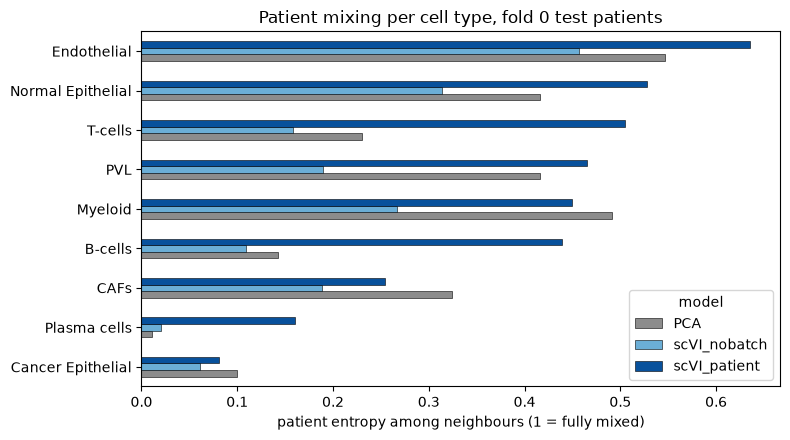

model,PCA,scVI_nobatch,scVI_patient
celltype,,,
Cancer Epithelial,0.099,0.061,0.081
Plasma cells,0.011,0.020,0.160
CAFs,0.324,0.188,0.254
B-cells,0.143,0.109,0.439
Myeloid,0.492,0.266,0.450
PVL,0.416,0.190,0.465
T-cells,0.230,0.158,0.505
Normal Epithelial,0.416,0.314,0.528
Endothelial,0.547,0.457,0.635


In [8]:
ct0, pat0 = adata.obs["celltype_major"].values[te0], adata.obs["donor_id"].values[te0]
rows_ct = []
for name, Z in Z0.items():
    for ct in pd.unique(ct0):
        mask = ct0 == ct
        if mask.sum() >= 100 and len(np.unique(pat0[mask])) > 1:
            rows_ct.append({"model": name, "celltype": ct,
                            "Patient_Entropy": M.compute_entropy(Z[mask], pat0[mask], k=50)})
per_ct = pd.DataFrame(rows_ct).pivot(index="celltype", columns="model", values="Patient_Entropy")[ORDER]
per_ct = per_ct.sort_values("scVI_patient")
per_ct.to_csv(OUT_DIR / "scvi_fold0_entropy_per_celltype.csv")
ax = per_ct.plot.barh(figsize=(8, 4.5), color=[colors[c] for c in ORDER], edgecolor="black", linewidth=0.4)
ax.set_xlabel("patient entropy among neighbours (1 = fully mixed)"); ax.set_ylabel("")
ax.set_title("Patient mixing per cell type, fold 0 test patients"); plt.tight_layout()
plt.savefig(OUT_DIR / "scvi_fold0_entropy_per_celltype.png", dpi=200); plt.show()
per_ct.round(3)

## UMAP of the test patients (fold 0)

Only a visualisation. The metric is above

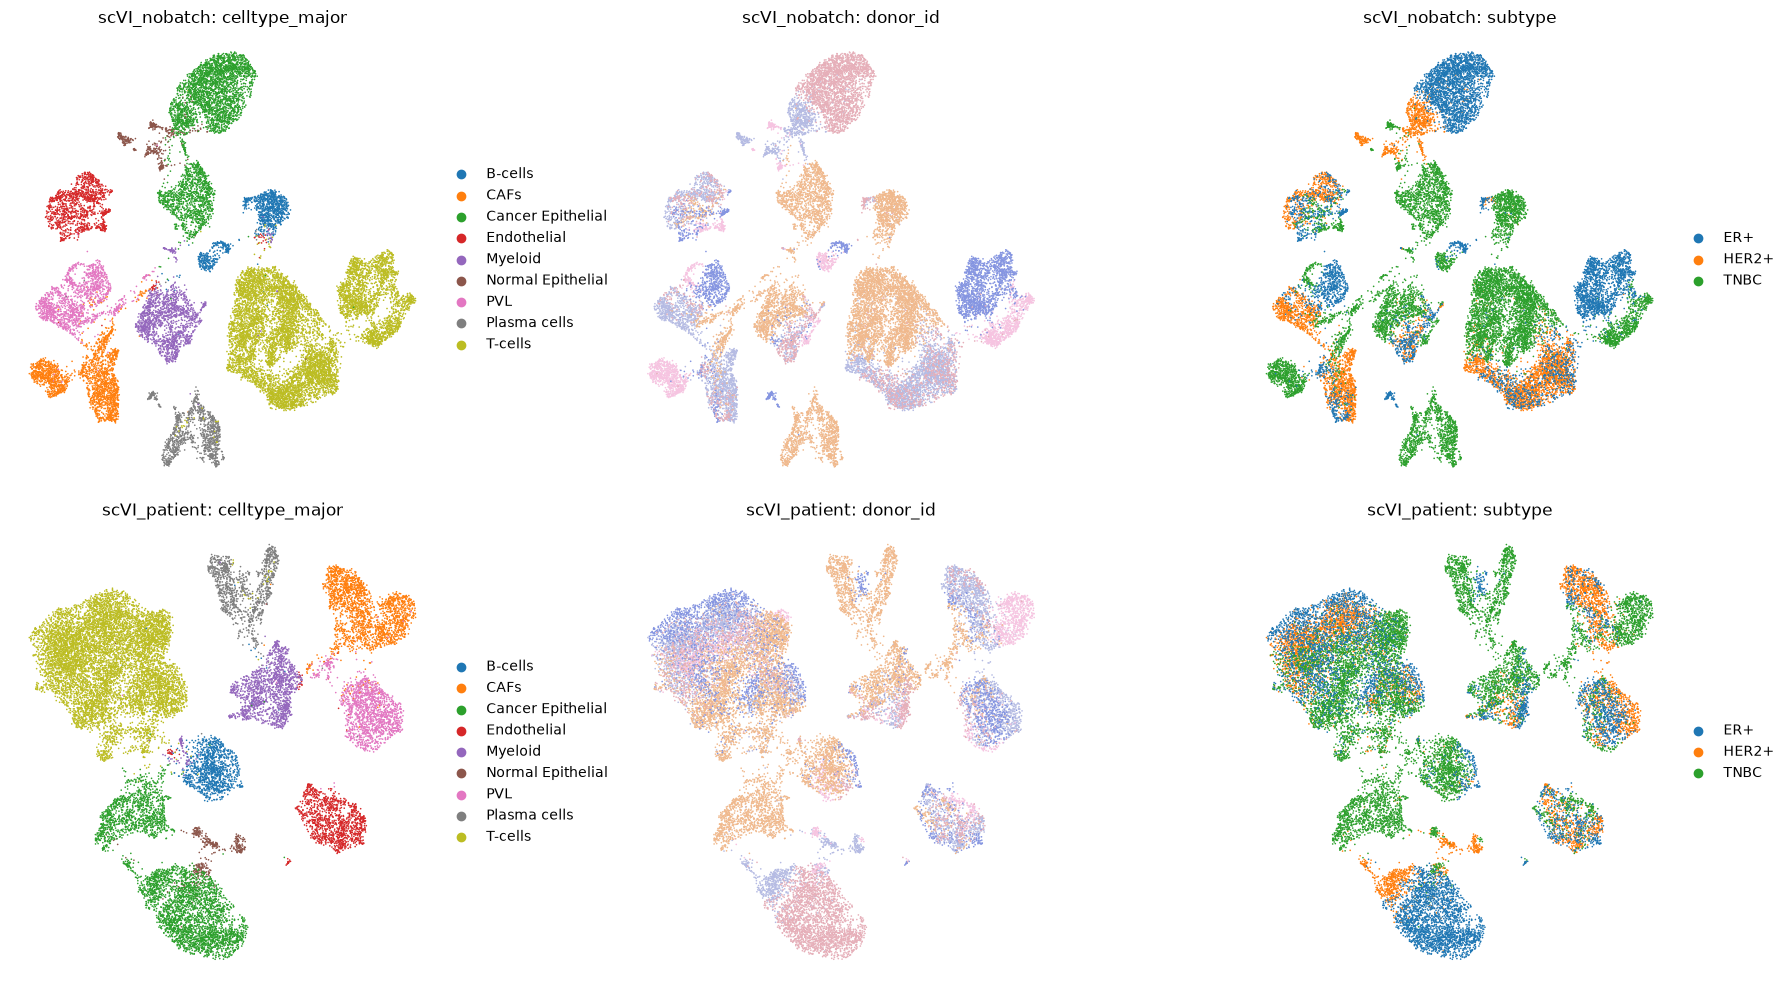

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
obs0 = adata.obs.iloc[np.where(te0)[0]].copy()
for r, name in enumerate(["scVI_nobatch", "scVI_patient"]):
    v = sc.AnnData(obs=obs0); v.obsm["Z"] = Z0[name]
    sc.pp.neighbors(v, use_rep="Z", random_state=S.SEED); sc.tl.umap(v, random_state=S.SEED)
    for c, col in enumerate(["celltype_major", "donor_id", "subtype"]):
        sc.pl.umap(v, color=col, ax=axes[r, c], show=False, title=f"{name}: {col}", frameon=False,
                   legend_loc="right margin" if col != "donor_id" else None)
plt.tight_layout(); plt.savefig(OUT_DIR / "scvi_fold0_umap.png", dpi=150); plt.show()

## Generative check: does scVI reproduce the counts? (fold 0, test patients)

For 5000 test cells we sample counts from the model and compare, gene by gene, the mean, the variance and the fraction of zeros with the real data.

- **Poisson null:** $x_{ng} \sim \mathrm{Poisson}(\ell_n p_g)$, with $\ell_n$ the cell's real library size and $p_g$ the gene's share of counts in the train cells. It has no cell types, so it is the floor any model must beat.
- **scVI (no batch):** posterior predictive samples. The batch-corrected variant is not used because its decoder needs the patient label, unknown for a new patient.

In [10]:
rng = np.random.default_rng(S.SEED)
idx = rng.choice(np.where(te0)[0], min(5000, te0.sum()), replace=False)
real = adata[idx, hvg0].X.toarray()
lib = real.sum(1, keepdims=True)

train0 = ~te0
p_g = np.asarray(adata[train0, hvg0].X.sum(0)).ravel(); p_g = p_g / p_g.sum()
sim_pois = rng.poisson(lib * p_g)

q0, a0 = query(m0, adata[idx, hvg0])
sim_scvi = q0.posterior_predictive_sample(a0, n_samples=1)
sim_scvi = np.asarray(sim_scvi.todense() if hasattr(sim_scvi, "todense") else sim_scvi).reshape(real.shape)

lg = lambda v: np.log10(v + 1e-4)
def ppc(real, sim):
    return {"MAE log10(mean)": np.abs(lg(real.mean(0)) - lg(sim.mean(0))).mean(),
            "MAE log10(var)": np.abs(lg(real.var(0)) - lg(sim.var(0))).mean(),
            "MAE zero fraction": np.abs((real == 0).mean(0) - (sim == 0).mean(0)).mean()}

ppc_tab = pd.DataFrame({"Poisson null": ppc(real, sim_pois), "scVI NB": ppc(real, sim_scvi)}).T
print(f"zero fraction: real {(real == 0).mean():.3f} | Poisson {(sim_pois == 0).mean():.3f} | scVI {(sim_scvi == 0).mean():.3f}")
ppc_tab.to_csv(OUT_DIR / "scvi_fold0_ppc.csv")
ppc_tab.round(4)

INFO     Found 100.0% reference vars in query data.                                                                


zero fraction: real 0.915 | Poisson 0.843 | scVI 0.911


,MAE log10(mean),MAE log10(var),MAE zero fraction
Poisson null,0.3053,0.6198,0.0736
scVI NB,0.2063,0.3749,0.0102


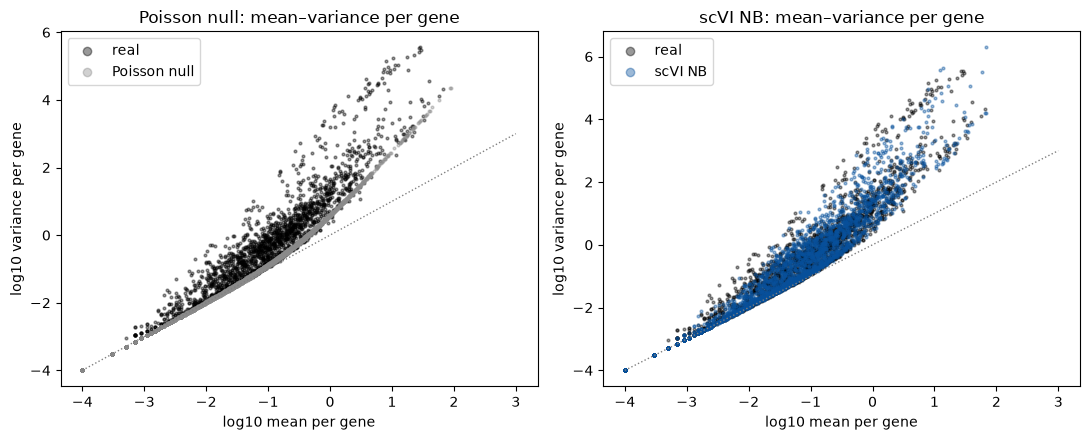

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (lab, sim, col) in zip(axes, [("Poisson null", sim_pois, "#8c8c8c"), ("scVI NB", sim_scvi, "#08519c")]):
    ax.scatter(lg(real.mean(0)), lg(real.var(0)), s=4, color="black", alpha=0.4, label="real")
    ax.scatter(lg(sim.mean(0)), lg(sim.var(0)), s=4, color=col, alpha=0.4, label=lab)
    ax.plot([-4, 3], [-4, 3], ls=":", color="gray", lw=1)
    ax.set(xlabel="log10 mean per gene", ylabel="log10 variance per gene", title=f"{lab}: mean–variance per gene")
    ax.legend(markerscale=3)
plt.tight_layout(); plt.savefig(OUT_DIR / "scvi_fold0_ppc.png", dpi=200); plt.show()

In [12]:
# Colab: download all results (CSV + PNG) as one zip
if IN_COLAB:
    import shutil
    from google.colab import files
    files.download(shutil.make_archive("/content/results_scvi", "zip", OUT_DIR))   # also kept in Drive/results_scvi